In [1]:
import casadi as cas

In [2]:
def dynamic_system(x, u):
    """
    Defines the dynamic system's equations.

    Args:
    x (casadi.MX): State vector.
    u (casadi.MX): Control input.

    Returns:
    casadi.MX: State derivative.
    """
    # Example: Simple pendulum dynamics
    g = 9.81  # Gravity (m/s^2)
    L = 1.0   # Pendulum length (m)

    theta = x[0]  # Angle (rad)
    theta_dot = x[1]  # Angular velocity (rad/s)

    theta_ddot = -g / L * cas.sin(theta) + u  # Angular acceleration (rad/s^2)

    return cas.vertcat(theta_dot, theta_ddot)

In [3]:
# Set up the optimization problem
N = 100  # Number of time steps
dt = 0.1  # Time step (s)

opti = cas.Opti()

In [4]:
# Define optimization variables
x = opti.variable(2, N+1)  # State trajectory
u = opti.variable(N)       # Control inputs

In [6]:
# Initial and final states
x_init = [0.1, 0.0]  # Initial state: [theta=0.1 rad, theta_dot=0 rad/s]
x_final = [0.0, 0.0] # Final state: [theta=0 rad, theta_dot=0 rad/s]

In [7]:
opti.minimize(cas.sumsqr(u))

In [8]:
for k in range(N):
    x_next = x[:, k] + dt * dynamic_system(x[:, k], u[k])
    opti.subject_to(x[:, k+1] == x_next)

In [ ]:
# Initial and final state constraints
opti.subject_to(x[:, 0] == x_init)
opti.subject_to(x[:, -1] == x_final)

In [9]:
# Control input constraints (optional)
u_min = -10.0  # Minimum control input
u_max = 10.0   # Maximum control input
opti.subject_to(u >= u_min)
opti.subject_to(u <= u_max)

In [10]:
# Solve the optimization problem
solver_opts = {'ipopt.print_level': 0, 'print_time': 0}
opti.solver('ipopt', solver_opts)
sol = opti.solve()


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



In [11]:
# Extract the optimal solution
x_opt = sol.value(x)
u_opt = sol.value(u)

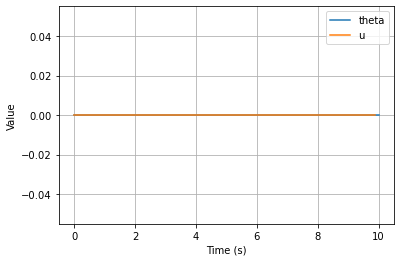

In [12]:
# Plot the results (optional)
import matplotlib.pyplot as plt

time = dt * cas.vertcat(range(N+1))
plt.figure()
plt.plot(time, x_opt[0, :].T, label='theta')
plt.plot(time[:-1], u_opt.T, label='u')
plt.xlabel('Time (s)')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
opti.debug.value(x)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0.]])